# 3. Симуляции: проверяем саму методику

Здесь проверяется не гипотеза о воротах, а инструменты: не врут ли наши тесты, хватало ли данных, что ломает подглядывание, как смотреть на результат по ходу теста без этой проблемы и что даёт CUPED, в том числе на реальных данных.

In [1]:
import sys
sys.path[:0] = ["src", "../src"]  # notebooks/src — стиль графиков, src — библиотека abtest
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
from scipy import stats
from abtest import stats as S
from abtest import sequential as Q
from _style import setup, num, pct, pp, pval, thousands, commas, CONTROL, NEUTRAL, TEXT, MUTED, METRIC
setup()

df = pd.read_csv("../data/cookie_cats.csv")
ctrl = df[df.version == "gate_30"].reset_index(drop=True)
A, B = df[df.version == "gate_30"], df[df.version == "gate_40"]
GATE_FREE = 29  # меньше 29 раундов — до ворот точно не дошёл (ноутбук 1)
rng = np.random.default_rng(42)

## 3.1. A/A-тесты: доля ложных срабатываний

Берём только контрольную группу и 5000 раз случайно делим её пополам. Настоящего эффекта нет, поэтому корректный тест должен находить «значимую разницу» примерно в 5% случаев, а p-value должны распределяться равномерно.

In [2]:
N_SIM = 5000  # z-тест почти бесплатный, тест Манна — Уитни на 22 тыс. × 22 тыс. — несколько мс на разбиение
r7 = ctrl.retention_7.values.astype(int)
rounds = ctrl.sum_gamerounds.values
n = len(ctrl); half = n // 2
p_z, p_mw = np.empty(N_SIM), np.empty(N_SIM)
for i in range(N_SIM):
    idx = rng.permutation(n)
    a, b = idx[:half], idx[half:]
    p_z[i] = S.two_proportion_test(r7[a].sum(), len(a), r7[b].sum(), len(b))["p_value"]
    p_mw[i] = stats.mannwhitneyu(rounds[b], rounds[a], alternative="two-sided").pvalue

def fpr_line(hits):
    k, m = int(np.sum(hits)), len(hits)
    lo, hi = stats.binomtest(k, m).proportion_ci(0.95)
    return f"{pct(k / m)} (95% ДИ {pct(lo)}–{pct(hi)})"

print("Доля ложных срабатываний при α = 0,05:")
print("  z-тест, retention_7:  ", fpr_line(p_z < 0.05))
print("  Манна — Уитни, раунды:", fpr_line(p_mw < 0.05))
print(f"Равномерность p-value (тест Колмогорова — Смирнова): z-тест p = {pval(stats.kstest(p_z, 'uniform').pvalue)}, "
      f"Манна — Уитни p = {pval(stats.kstest(p_mw, 'uniform').pvalue)}")

# Для z-теста долю ложных срабатываний можно посчитать точно: при делении фиксированной группы пополам
# число вернувшихся в первой половине имеет гипергеометрическое распределение
K7 = r7.sum()
xs_all = np.arange(max(0, K7 - (n - half)), min(K7, half) + 1)
pmf = stats.hypergeom.pmf(xs_all, n, K7, half)
p_exact = np.array([S.two_proportion_test(x, half, K7 - x, n - half)["p_value"] for x in xs_all])
print(f"\nТочная доля ложных срабатываний z-теста (без симуляции): {pct(pmf[p_exact < 0.05].sum(), 2)}")
print(f"p-value z-теста дискретны: самое частое значение (около 1) выпадает с вероятностью {pct(2 * pmf.max())}")

Доля ложных срабатываний при α = 0,05:
  z-тест, retention_7:   4,3% (95% ДИ 3,8%–4,9%)
  Манна — Уитни, раунды: 5,0% (95% ДИ 4,4%–5,6%)
Равномерность p-value (тест Колмогорова — Смирнова): z-тест p = 0,017, Манна — Уитни p = 0,234

Точная доля ложных срабатываний z-теста (без симуляции): 4,95%
p-value z-теста дискретны: самое частое значение (около 1) выпадает с вероятностью 1,9%


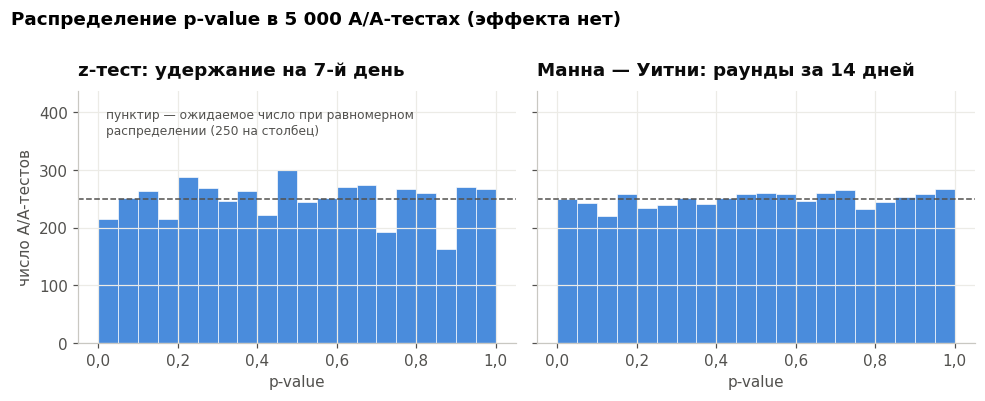

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, p, name in [(axes[0], p_z, "z-тест: " + METRIC["retention_7"]),
                    (axes[1], p_mw, "Манна — Уитни: " + METRIC["sum_gamerounds"])]:
    ax.hist(p, bins=20, range=(0, 1), color=CONTROL, alpha=0.85, edgecolor="white", linewidth=0.5)
    ax.axhline(N_SIM / 20, color=MUTED, ls="--", lw=1)
    ax.set(title=name, xlabel="p-value")
    ax.title.set_fontsize(10.5)
    commas(ax)
axes[0].set_ylabel("число A/A-тестов")
axes[0].set_ylim(0, N_SIM / 20 * 1.75)
axes[0].text(0.02, N_SIM / 20 * 1.45, f"пунктир — ожидаемое число при равномерном\nраспределении ({thousands(N_SIM / 20)} на столбец)",
             fontsize=8, color=MUTED)
fig.suptitle(f"Распределение p-value в {thousands(N_SIM)} A/A-тестах (эффекта нет)", x=0.01, ha="left", fontweight="bold", y=1.0)
fig.tight_layout()

Тест Манна — Уитни даёт 5,0% ложных срабатываний, и распределение его p-value равномерное (тест Колмогорова — Смирнова не отвергает это, p = 0,23).

У z-теста в этих 5000 разбиениях 4,3%, и 95% ДИ немного не дотягивает до 5%. Но для z-теста долю можно посчитать точно, без симуляции: при делении фиксированной группы пополам число вернувшихся в одной половине подчиняется гипергеометрическому распределению. Точная доля — 4,95%, так что 4,3% — шум Монте-Карло (отклонение около двух стандартных ошибок). Тест Колмогорова — Смирнова для z-теста равномерность отвергает (p = 0,017) по другой причине: число вернувшихся целое, поэтому p-value принимают отдельные значения, и самое частое из них (около 1) выпадает с вероятностью 1,9%. KS рассчитан на непрерывное распределение и при 5000 повторениях такие ступеньки замечает. На участке p < 0,05, который важен для решения, оба теста работают как заявлено, так что значимый результат по `retention_7` не артефакт метода.

## 3.2. Мощность и минимальный детектируемый эффект (MDE)

MDE — самый маленький эффект, который тест такого размера заметит с вероятностью 80% при α = 0,05. Если реальный эффект меньше MDE, тест, скорее всего, его пропустит.

In [4]:
n_a, n_b = len(A), len(B)
for m in ["retention_7", "retention_1"]:
    d = B[m].mean() - A[m].mean()
    print(f"{m}: база {pct(A[m].mean())}, MDE = {num(S.mde_proportion(A[m].mean(), n_a, n_b) * 100)} п.п., "
          f"наблюдаемая разница {pp(d)} п.п.")
obs = B.retention_7.mean() - A.retention_7.mean()
p0 = A.retention_7.mean(); p1 = p0 + obs
print(f"\nМощность теста для эффекта {num(abs(obs) * 100)} п.п. (наблюдаемого): {pct(S.power_proportion(p0, abs(obs), n_a, n_b), 0)}")
print(f"Мощность, если истинный эффект 0,6 п.п.: {pct(S.power_proportion(p0, 0.006, n_a, n_b), 0)}")

# Оценка с поправкой на дисбаланс до ворот (ноутбук 2, раздел 2.6): пост-стратификация по min(раунды, 29)
ps = {m: S.poststratified_diff(A[m].values, np.minimum(A.sum_gamerounds.values, GATE_FREE),
                               B[m].values, np.minimum(B.sum_gamerounds.values, GATE_FREE))
      for m in ["retention_7", "retention_1"]}
z_sum = stats.norm.ppf(0.975) + stats.norm.ppf(0.8)          # MDE = (z_0,975 + z_0,8) · SE
ci_raw = S.two_proportion_test(A.retention_7.sum(), n_a, B.retention_7.sum(), n_b)["ci"]
se_raw = (ci_raw[1] - ci_raw[0]) / (2 * stats.norm.ppf(0.975))   # та же формула SE, что у пост-стратификации
se_adj = ps["retention_7"]["se"]
mde_raw, mde_adj = z_sum * se_raw, z_sum * se_adj
power_adj = stats.norm.sf(stats.norm.ppf(0.975) - abs(ps["retention_7"]["diff"]) / se_adj)
print(f"\nretention_7 с поправкой на дисбаланс до ворот: {pp(ps['retention_7']['diff'])} п.п., p = {pval(ps['retention_7']['p_value'])}")
print(f"  SE разницы: без поправки {num(se_raw * 100, 3)} п.п., с поправкой {num(se_adj * 100, 3)} п.п.")
print(f"  MDE: без поправки {num(mde_raw * 100)} п.п., с поправкой {num(mde_adj * 100)} п.п.")
print(f"  мощность скорректированной оценки для эффекта {num(abs(ps['retention_7']['diff']) * 100)} п.п.: {pct(power_adj, 0)}")
print(f"retention_1 с поправкой: {pp(ps['retention_1']['diff'])} п.п., p = {pval(ps['retention_1']['p_value'])}")

retention_7: база 19,0%, MDE = 0,73 п.п., наблюдаемая разница −0,82 п.п.
retention_1: база 44,8%, MDE = 0,93 п.п., наблюдаемая разница −0,59 п.п.

Мощность теста для эффекта 0,82 п.п. (наблюдаемого): 88%
Мощность, если истинный эффект 0,6 п.п.: 63%

retention_7 с поправкой на дисбаланс до ворот: −0,50 п.п., p = 0,026
  SE разницы: без поправки 0,259 п.п., с поправкой 0,226 п.п.
  MDE: без поправки 0,73 п.п., с поправкой 0,63 п.п.
  мощность скорректированной оценки для эффекта 0,50 п.п.: 61%
retention_1 с поправкой: −0,02 п.п., p = 0,952


Проверим формулу мощности симуляцией: генерируем 2000 синтетических тестов, где эффект на самом деле равен наблюдаемому (−0,82 п.п.), и считаем, в какой доле тест его находит.

In [5]:
xa = rng.binomial(n_a, p0, 2000); xb = rng.binomial(n_b, p1, 2000)
hits = np.mean([S.two_proportion_test(x1, n_a, x2, n_b)["p_value"] < 0.05 for x1, x2 in zip(xa, xb)])
print(f"Эмпирическая мощность: {pct(hits, 0)} (формула: {pct(S.power_proportion(p0, abs(obs), n_a, n_b), 0)})")

Эмпирическая мощность: 89% (формула: 88%)


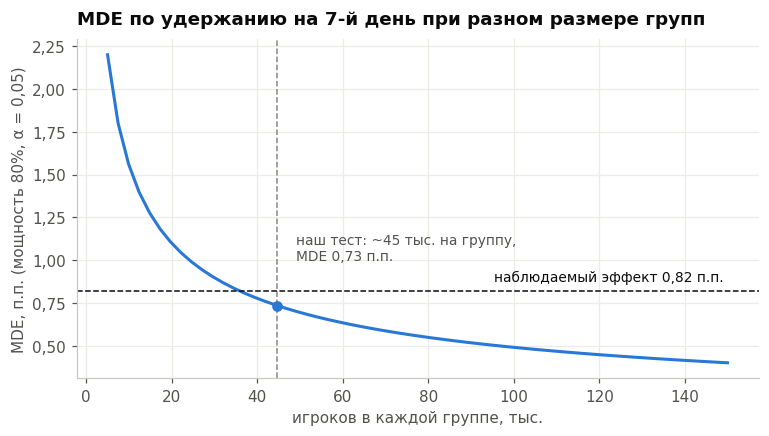

In [6]:
ns = np.linspace(5_000, 150_000, 60)
mde_ours = S.mde_proportion(p0, n_a, n_b) * 100
fig, ax = plt.subplots()
ax.plot(ns / 1000, [S.mde_proportion(p0, int(k)) * 100 for k in ns], color=CONTROL)
ax.axvline(n_a / 1000, color=NEUTRAL, ls="--", lw=1)
ax.axhline(abs(obs) * 100, color=TEXT, ls="--", lw=1)
ax.plot(n_a / 1000, mde_ours, "o", color=CONTROL, ms=6, zorder=3)
ax.annotate(f"наш тест: ~{n_a / 1000:.0f} тыс. на группу,\nMDE {num(mde_ours)} п.п.", (n_a / 1000, mde_ours),
            xytext=(12, 30), textcoords="offset points", fontsize=9, color=MUTED)
ax.text(149, abs(obs) * 100 + 0.06, f"наблюдаемый эффект {num(abs(obs) * 100)} п.п.", fontsize=9, color=TEXT, ha="right")
ax.set(title="MDE по удержанию на 7-й день при разном размере групп",
       xlabel="игроков в каждой группе, тыс.", ylabel="MDE, п.п. (мощность 80%, α = 0,05)")
commas(ax)

MDE по 7-дневному удержанию ≈ 0,73 п.п., наблюдаемая разница −0,82 п.п. превышает его ненамного. Запас небольшой: при истинном эффекте 0,6 п.п. мощность была бы около 63%. Мощность «для наблюдаемого эффекта» (88%) служит проверкой формулы симуляцией, а не дополнительным аргументом за результат: она однозначно связана с p-value.

Оценка с поправкой на дисбаланс до ворот (ноутбук 2, раздел 2.6) меньше: −0,50 п.п., то есть ниже MDE простого сравнения. Но скорректированная оценка и точнее: её стандартная ошибка 0,226 п.п. против 0,259, поэтому её собственный MDE ≈ 0,63 п.п. Разница −0,50 п.п. ниже и этой границы: значимость есть (p = 0,026), но эффект такого размера тест находил бы лишь примерно в 61% случаев. Запаса по мощности у скорректированного вывода нет.

По 1-дневному удержанию наблюдаемая разница −0,59 п.п. меньше MDE 0,93 п.п. Значит, незначимый результат ожидаем, даже если эффект такого размера реален: тест не позволяет ни подтвердить его, ни исключить. После поправки на дисбаланс до ворот разница по 1-му дню исчезает совсем (−0,02 п.п., p = 0,95).

## 3.3. Подглядывание (peeking)

Подглядывание — это когда на p-value смотрят каждый день и останавливают тест, как только стало «значимо». Дат в данных нет, поэтому принимаем допущение: случайный порядок игроков считаем порядком прихода. Проверяем на A/A-данных (эффекта нет): смотрим на результат после каждых 1000 новых игроков и останавливаемся при первом p < 0,05.

In [7]:
def peeking_z(y, n_sims=1000, step=1000, seed=0):
    """z-статистики A/A-теста после каждых step игроков: матрица симуляции × проверки."""
    rg = np.random.default_rng(seed)
    looks = np.arange(step, len(y) + 1, step) - 1
    z = np.empty((n_sims, len(looks)))
    for s in range(n_sims):
        order = rg.permutation(len(y))
        grp = rg.integers(0, 2, len(y)).astype(bool)          # случайное назначение в A/B по мере прихода
        yy = y[order]
        ca, cb = np.cumsum(yy * ~grp)[looks], np.cumsum(yy * grp)[looks]
        na, nb = np.cumsum(~grp)[looks], np.cumsum(grp)[looks]
        p_pool = (ca + cb) / (na + nb)
        z[s] = (cb / nb - ca / na) / np.sqrt(p_pool * (1 - p_pool) * (1 / na + 1 / nb))
    return looks + 1, z

look_n, z_aa = peeking_z(r7)
n_looks = z_aa.shape[1]
p_aa = 2 * stats.norm.sf(np.abs(z_aa))
print(f"Проверок за тест: {n_looks}")
print(f"Ложные срабатывания, если смотреть один раз в конце: {pct((p_aa[:, -1] < 0.05).mean())}")
print(f"Ложные срабатывания при подглядывании каждые 1000 игроков: {pct((p_aa < 0.05).any(axis=1).mean())}")
print(f"С поправкой Бонферрони на число проверок (α/{n_looks}): {pct((p_aa < 0.05 / n_looks).any(axis=1).mean())}")

Проверок за тест: 44
Ложные срабатывания, если смотреть один раз в конце: 5,4%
Ложные срабатывания при подглядывании каждые 1000 игроков: 30,9%
С поправкой Бонферрони на число проверок (α/44): 1,6%


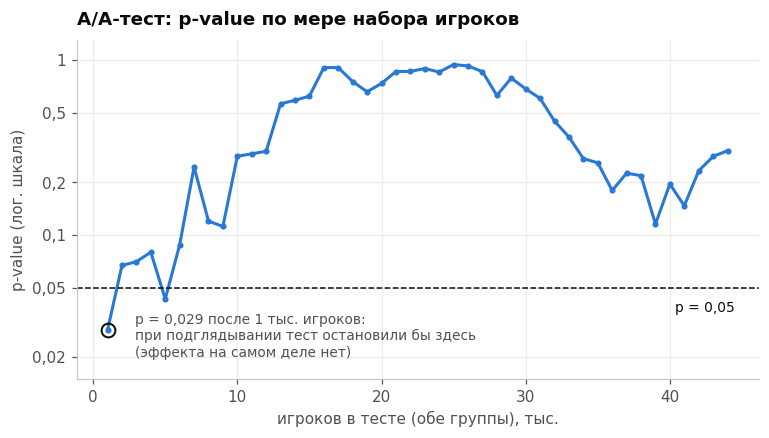

In [8]:
p = p_aa[0]
first = int(np.argmax(p < 0.05))
fig, ax = plt.subplots()
ax.plot(look_n / 1000, p, color=CONTROL, marker="o", ms=3)
ax.axhline(0.05, color=TEXT, ls="--", lw=1)
ax.text(44.5, 0.042, "p = 0,05", color=TEXT, fontsize=9, ha="right", va="top")
ax.plot(look_n[first] / 1000, p[first], "o", ms=9, mfc="none", mec=TEXT, mew=1.3)
ax.annotate(f"p = {num(p[first], 3)} после {look_n[first] / 1000:.0f} тыс. игроков:\nпри подглядывании тест остановили бы здесь\n(эффекта на самом деле нет)",
            (look_n[first] / 1000, p[first]), xytext=(18, -4), textcoords="offset points", fontsize=9, color=MUTED, va="center")
ax.set_yscale("log")
ax.set_ylim(0.015, 1.3)
ax.yaxis.set_major_locator(FixedLocator([0.02, 0.05, 0.1, 0.2, 0.5, 1]))
ax.yaxis.set_minor_locator(NullLocator())
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: num(v, 2).rstrip("0").rstrip(",")))
ax.set(title="A/A-тест: p-value по мере набора игроков",
       xlabel="игроков в тесте (обе группы), тыс.", ylabel="p-value (лог. шкала)")

При подглядывании «победа» в тесте без всякого эффекта находится в 30,9% случаев вместо заявленных 5%. На графике пример: p-value падает ниже 0,05 на первой же проверке, а к концу теста поднимается до 0,3. Правильно — заранее зафиксировать размер выборки (калькулятор в `docs/`) и смотреть результат один раз. Простая поправка Бонферрони на число проверок возвращает ложные срабатывания под контроль, но с запасом (1,6% вместо 5%), то есть ценой мощности. Если смотреть по ходу теста всё-таки нужно, есть последовательные дизайны с заранее рассчитанными границами — о них раздел 3.4.

## 3.4. Как смотреть на результат по ходу теста правильно

Групповой последовательный дизайн: число проверок K задаётся заранее, и на каждой проверке z-статистика сравнивается не с 1,96, а со своей границей. Границы подобраны так, чтобы вероятность хотя бы раз выйти за них без эффекта была ровно 5% (реализация — `src/abtest/sequential.py`, константа калибруется симуляцией).

- **O'Brien–Fleming**: c_k = C·√(K/k). В начале теста граница очень высокая, к концу опускается почти до обычной. Остановиться рано можно только при огромном эффекте.
- **Pocock**: c_k = C, одинаковая строгая граница на всех проверках.

Берём те же 44 проверки, что и в разделе 3.3.

In [9]:
obf = Q.boundaries(n_looks, kind="obf")
poc = Q.boundaries(n_looks, kind="pocock")
for b, name in [(obf, "O'Brien–Fleming"), (poc, "Pocock")]:
    print(f"{name:16} граница |z|: первая проверка {num(b['z'][0])}, последняя {num(b['z'][-1])} "
          f"(порог p на последней: {num(b['p_nominal'][-1], 4)})")

print(f"\nЛожные срабатывания на тех же {len(z_aa)} A/A-симуляциях, что и в 3.3:")
print("  подглядывание с порогом 1,96:", fpr_line((p_aa < 0.05).any(axis=1)))
print("  O'Brien–Fleming:             ", fpr_line(Q.first_crossing(z_aa, obf) > 0))
print("  Pocock:                      ", fpr_line(Q.first_crossing(z_aa, poc) > 0))

O'Brien–Fleming  граница |z|: первая проверка 14,34, последняя 2,16 (порог p на последней: 0,0306)
Pocock           граница |z|: первая проверка 2,78, последняя 2,78 (порог p на последней: 0,0054)

Ложные срабатывания на тех же 1000 A/A-симуляциях, что и в 3.3:
  подглядывание с порогом 1,96: 30,9% (95% ДИ 28,0%–33,9%)
  O'Brien–Fleming:              5,2% (95% ДИ 3,9%–6,8%)
  Pocock:                       4,3% (95% ДИ 3,1%–5,7%)


Ложные срабатывания вернулись к 5% в пределах точности симуляции. Теперь посмотрим, чем за это платят. Генерируем 20 000 тестов размера Cookie Cats (44 700 и 45 489 игроков), в которых эффект на удержание 7-го дня на самом деле равен наблюдаемому (−0,82 п.п.), и на каждом проводим 44 равномерные проверки.

In [10]:
N_H1 = 20_000
k = np.arange(1, n_looks + 1)
cum_a = np.round(n_a * k / n_looks).astype(int); cum_b = np.round(n_b * k / n_looks).astype(int)
rg = np.random.default_rng(7)
xa = np.cumsum(rg.binomial(np.diff(cum_a, prepend=0), p0, (N_H1, n_looks)), axis=1)
xb = np.cumsum(rg.binomial(np.diff(cum_b, prepend=0), p1, (N_H1, n_looks)), axis=1)
p_pool = (xa + xb) / (cum_a + cum_b)
z_h1 = (xb / cum_b - xa / cum_a) / np.sqrt(p_pool * (1 - p_pool) * (1 / cum_a + 1 / cum_b))
n_total = cum_a + cum_b

diff_h1 = xb / cum_b - xa / cum_a
sig_fixed = np.abs(z_h1[:, -1]) >= stats.norm.ppf(0.975)
rows = [{"дизайн": "фиксированный (один взгляд в конце)", "мощность": sig_fixed.mean(),
         "остановлено досрочно": 0.0, "средняя выборка, тыс. игроков": n_total[-1] / 1000, "средняя выборка, % от полной": 1.0,
         "средняя оценка среди значимых, п.п.": diff_h1[sig_fixed, -1].mean() * 100}]
stop = {}
for b, name in [(obf, "O'Brien–Fleming"), (poc, "Pocock")]:
    look = Q.first_crossing(z_h1, b)
    stop[b["kind"]] = look
    ok = look > 0
    n_used = n_total[np.where(ok, look, n_looks) - 1]
    rows.append({"дизайн": name, "мощность": ok.mean(), "остановлено досрочно": (ok & (look < n_looks)).mean(),
                 "средняя выборка, тыс. игроков": n_used.mean() / 1000, "средняя выборка, % от полной": n_used.mean() / n_total[-1],
                 "средняя оценка среди значимых, п.п.": diff_h1[np.flatnonzero(ok), look[ok] - 1].mean() * 100})
res = pd.DataFrame(rows).set_index("дизайн")
med = {kd: int(np.median(stop[kd][stop[kd] > 0])) for kd in stop}
print(f"Истинный эффект в симуляции: {pp(obs)} п.п.; выборка — обе группы вместе")
print(f"Медианная проверка остановки среди сработавших тестов: O'Brien–Fleming — {med['obf']}-я "
      f"({n_total[med['obf'] - 1] / 1000:.0f} тыс. игроков), Pocock — {med['pocock']}-я ({n_total[med['pocock'] - 1] / 1000:.0f} тыс. игроков)\n")
res_show = res.copy()
for col in ["мощность", "остановлено досрочно"]:
    res_show[col] = res_show[col].map(pct)
res_show["средняя выборка, тыс. игроков"] = res_show["средняя выборка, тыс. игроков"].map(lambda v: num(v, 1))
res_show["средняя выборка, % от полной"] = res_show["средняя выборка, % от полной"].map(lambda v: pct(v, 0))
res_show["средняя оценка среди значимых, п.п."] = res_show["средняя оценка среди значимых, п.п."].map(lambda v: num(v, sign=True))
res_show

Истинный эффект в симуляции: −0,82 п.п.; выборка — обе группы вместе
Медианная проверка остановки среди сработавших тестов: O'Brien–Fleming — 28-я (57 тыс. игроков), Pocock — 21-я (43 тыс. игроков)



,мощность,остановлено досрочно,"средняя выборка, тыс. игроков","средняя выборка, % от полной","средняя оценка среди значимых, п.п."
дизайн,,,,,
фиксированный (один взгляд в конце),"88,4%","0,0%","90,2",100%,"−0,88"
O'Brien–Fleming,"86,7%","85,3%","62,1",69%,"−1,00"
Pocock,"74,8%","73,7%","55,6",62%,"−1,35"


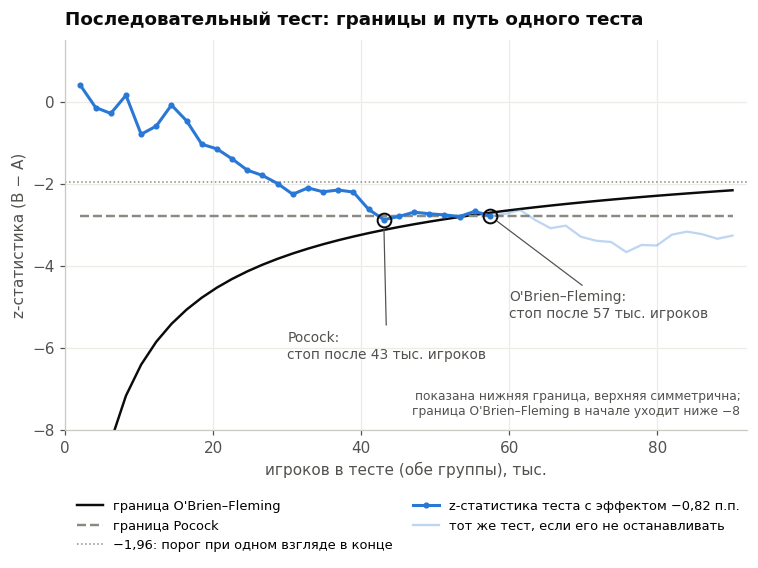

In [11]:
# Пример — «типичный» тест: обе схемы останавливают его на своей медианной проверке
i = int(np.flatnonzero((stop["obf"] == med["obf"]) & (stop["pocock"] == med["pocock"]))[0])
z_i, xs = z_h1[i], n_total / 1000
k_obf, k_poc = stop["obf"][i], stop["pocock"][i]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(xs, -obf["z"], color=TEXT, lw=1.6, label="граница O'Brien–Fleming")
ax.plot(xs, -poc["z"], color=NEUTRAL, lw=1.6, ls="--", label="граница Pocock")
ax.axhline(-1.96, color=NEUTRAL, lw=1, ls=":", label="−1,96: порог при одном взгляде в конце")
ax.plot(xs[:k_obf], z_i[:k_obf], color=CONTROL, marker="o", ms=3, label="z-статистика теста с эффектом −0,82 п.п.")
ax.plot(xs[k_obf - 1:], z_i[k_obf - 1:], color=CONTROL, alpha=0.3, lw=1.5, label="тот же тест, если его не останавливать")
for kk, name, xy_text in [(k_poc, "Pocock", (30, -5.6)), (k_obf, "O'Brien–Fleming", (60, -4.6))]:
    ax.plot(xs[kk - 1], z_i[kk - 1], "o", ms=9, mfc="none", mec=TEXT, mew=1.3)
    ax.annotate(f"{name}:\nстоп после {xs[kk - 1]:.0f} тыс. игроков", (xs[kk - 1], z_i[kk - 1]),
                xytext=xy_text, textcoords="data", ha="left", va="top", fontsize=9, color=MUTED,
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8, shrinkB=6))
ax.text(0.99, 0.03, "показана нижняя граница, верхняя симметрична;\nграница O'Brien–Fleming в начале уходит ниже −8",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color=MUTED)
ax.set_ylim(-8, 1.5)
ax.set_xlim(0, xs[-1] + 2)
ax.set(title="Последовательный тест: границы и путь одного теста",
       xlabel="игроков в тесте (обе группы), тыс.", ylabel="z-статистика (B − A)")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.15), ncol=2, fontsize=8.5, columnspacing=1.5)
commas(ax)

Обе схемы держат ложные срабатывания около 5% при 44 проверках, а не 30,9%, как подглядывание с обычным порогом. Отличаются они ценой.

O'Brien–Fleming почти ничего не стоит по мощности: 86,7% против 88,4% у фиксированного дизайна. Граница на последней проверке 2,16 вместо 1,96, но до неё доходит меньше 15% тестов. При эффекте −0,82 п.п. 85,3% тестов останавливаются досрочно, и в среднем тест заканчивается на 69% от полной выборки. Pocock останавливает раньше (в среднем 62% выборки), но его строгий порог |z| > 2,78 на каждой проверке снижает мощность до 74,8%. Чтобы её вернуть, максимальный размер теста пришлось бы увеличить.

Ограничения. Экономия выборки появляется только при настоящем эффекте: без эффекта около 95% тестов идут до конца. Число и моменты проверок нужно зафиксировать до старта: эти границы рассчитаны на 44 равных шага, при неравномерных проверках нужны функции расходования α Лана — ДеМетса. Допущение раздела 3.3 о порядке прихода игроков здесь тоже действует.

Оценка эффекта среди значимых тестов завышена при любом дизайне: отбирая только значимые результаты, мы отбираем и те, где случайность сыграла в сторону эффекта. В фиксированном дизайне средняя оценка среди значимых тестов −0,88 п.п. при истинных −0,82. Ранняя остановка усиливает это смещение: −1,00 п.п. у O'Brien–Fleming и −1,35 п.п. у Pocock. Поэтому оценку после ранней остановки нужно корректировать или хотя бы не принимать за чистую монету, особенно для Pocock.

Для Cookie Cats это значит следующее: если истинный эффект близок к наблюдаемому, тест по O'Brien–Fleming в среднем закончился бы на 62 тыс. игроков (обе группы) вместо 90 тыс., с той же гарантией 5% ложных срабатываний и почти той же мощностью.

## 3.5. CUPED: меньше дисперсия — меньше нужная выборка

CUPED уменьшает дисперсию метрики с помощью ковариаты x, на которую воздействие не влияет: y' = y − θ·(x − x̄), где θ = cov(x, y) / var(x) считается по обеим группам вместе. Среднее по всем игрокам не меняется, а дисперсия падает примерно в (1 − ρ²) раз, где ρ — корреляция x и y. Обычно x — та же метрика за период до эксперимента.

Сначала механика на синтетике, где такая метрика есть и ρ ≈ 0,7.

In [12]:
def synth(n, effect, rho=0.7, seed=0):
    rg = np.random.default_rng(seed)
    x = rg.lognormal(3, 0.8, n)                                   # раунды за неделю ДО теста
    noise = rg.lognormal(3, 0.8, n)
    y = rho * x + np.sqrt(1 - rho ** 2) * noise                   # раунды во время теста
    grp = rg.integers(0, 2, n).astype(bool)
    y = y + effect * grp
    return x, y, grp

ci_plain, ci_cuped, pw_plain, pw_cuped = [], [], [], []
for s in range(500):
    x, y, g = synth(20_000, effect=1.0, seed=s)
    y2, _ = S.cuped(y, x)
    for arr, ci_list, pw in [(y, ci_plain, pw_plain), (y2, ci_cuped, pw_cuped)]:
        t = stats.ttest_ind(arr[g], arr[~g], equal_var=False)
        ci = t.confidence_interval()
        ci_list.append(ci.high - ci.low); pw.append(t.pvalue < 0.05)
x, y, g = synth(20_000, effect=0, seed=999)
rho = np.corrcoef(x, y)[0, 1]
print(f"Корреляция «до» и «во время»: ρ = {num(rho)} → ожидаемое снижение дисперсии ≈ {pct(rho ** 2, 0)}")
print(f"Ширина 95% ДИ эффекта: без CUPED {num(np.mean(ci_plain))}, с CUPED {num(np.mean(ci_cuped))} "
      f"({pct(1 - np.mean(ci_cuped) / np.mean(ci_plain), 0)} уже)")
print(f"Мощность при эффекте +1 раунд: без CUPED {pct(np.mean(pw_plain), 0)}, с CUPED {pct(np.mean(pw_cuped), 0)}")
print(f"Нужная выборка для той же мощности: ×{num(np.mean(ci_cuped) ** 2 / np.mean(ci_plain) ** 2)} от исходной")

Корреляция «до» и «во время»: ρ = 0,71 → ожидаемое снижение дисперсии ≈ 50%
Ширина 95% ДИ эффекта: без CUPED 1,45, с CUPED 1,04 (29% уже)
Мощность при эффекте +1 раунд: без CUPED 78%, с CUPED 97%
Нужная выборка для той же мощности: ×0,51 от исходной


При корреляции около 0,7 CUPED сужает доверительный интервал на 29% и сокращает нужную выборку примерно вдвое (×0,51).

### CUPED на данных Cookie Cats

Метрик до эксперимента в данных нет: в тест попадают новые игроки. Но есть ковариата, на которую ворота повлиять не могут: x = min(`sum_gamerounds`, 29). Она измерена во время теста, однако на каждый уровень нужен хотя бы один раунд (раундов не меньше, чем пройдено уровней). Поэтому, пока игрок не сыграл 29 раундов, он ни одних ворот не видел и обе версии игры для него одинаковы: сколько раундов до 29 он сыграет, от положения ворот не зависит. Условие то же, что в разделе 2.6 ноутбука 2: игрок не знает о воротах заранее. Сам `sum_gamerounds` целиком брать нельзя: после 29 раундов он уже может зависеть от группы.

Оговорка: ковариату выбрали после того, как в ноутбуке 1 увидели дисбаланс до ворот. В следующем тесте её стоит указать в плане анализа заранее.

In [13]:
x_all = np.minimum(df.sum_gamerounds.values, GATE_FREE).astype(float)
g_all = (df.version == "gate_40").values
q975 = stats.norm.ppf(0.975)

def diff_se(v):
    """Разница средних B − A и её стандартная ошибка (дисперсии групп раздельно)."""
    a, b = v[~g_all], v[g_all]
    return b.mean() - a.mean(), np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))

print(f"Доля игроков с < {GATE_FREE} раундов: контроль {pct((x_all[~g_all] < GATE_FREE).mean(), 2)}, "
      f"тест {pct((x_all[g_all] < GATE_FREE).mean(), 2)}")
print(f"Среднее x: контроль {num(x_all[~g_all].mean(), 3)}, тест {num(x_all[g_all].mean(), 3)} "
      f"(разница {num(x_all[g_all].mean() - x_all[~g_all].mean(), 3, sign=True)} раунда)\n")
rows, cuped_res = [], {}
for m in ["retention_7", "retention_1"]:
    y = df[m].values.astype(float)
    y_cuped, theta = S.cuped(y, x_all)
    rho = np.corrcoef(x_all, y)[0, 1]
    (d0, se0), (d1, se1) = diff_se(y), diff_se(y_cuped)
    shift = -theta * (x_all[g_all].mean() - x_all[~g_all].mean())
    cuped_res[m] = dict(rho=rho, var_red=1 - se1 ** 2 / se0 ** 2, d=d1, se=se1, shift=shift)
    print(f"{METRIC[m]}: ρ = {num(rho)}, θ = {num(theta, 4)}; дисперсия разницы ниже на {pct(1 - se1 ** 2 / se0 ** 2, 0)}, "
          f"ДИ уже на {pct(1 - se1 / se0, 0)}; сдвиг оценки −θ·(x̄_B − x̄_A) = {pp(shift)} п.п.")
    for name, d, se in [("без поправки", d0, se0), ("CUPED", d1, se1),
                        ("пост-стратификация (ноутбук 2, 2.6)", ps[m]["diff"], ps[m]["se"])]:
        rows.append({"метрика": METRIC[m], "оценка": name, "разница, п.п.": pp(d),
                     "95% ДИ, п.п.": f"[{pp(d - q975 * se)}; {pp(d + q975 * se)}]",
                     "ширина ДИ, п.п.": num(2 * q975 * se * 100), "p-value": pval(2 * stats.norm.sf(abs(d / se)))})
pd.DataFrame(rows).set_index(["метрика", "оценка"])

Доля игроков с < 29 раундов: контроль 62,06%, тест 62,80%
Среднее x: контроль 16,656, тест 16,434 (разница −0,222 раунда)

удержание на 7-й день: ρ = 0,45, θ = 0,0151; дисперсия разницы ниже на 20%, ДИ уже на 10%; сдвиг оценки −θ·(x̄_B − x̄_A) = +0,34 п.п.
удержание на 1-й день: ρ = 0,62, θ = 0,0269; дисперсия разницы ниже на 38%, ДИ уже на 21%; сдвиг оценки −θ·(x̄_B − x̄_A) = +0,60 п.п.


разница, п.п.    95% ДИ, п.п. ширина ДИ, п.п. p-value
метрика               оценка                                                                                   
удержание на 7-й день без поправки                                −0,82  [−1,33; −0,31]            1,02  0,0016
                      CUPED                                       −0,48  [−0,94; −0,03]            0,91   0,037
                      пост-стратификация (ноутбук 2, 2.6)         −0,50  [−0,95; −0,06]            0,89   0,026
удержание на 1-й день без поправки                                −0,59  [−1,24; +0,06]            1,30   0,074
                      CUPED                                       +0,01  [−0,50; +0,52]            1,02   0,980
                      пост-стратификация (ноутбук 2, 2.6)         −0,02  [−0,52; +0,49]            1,02   0,952

Корреляция умеренная (ρ = 0,45 для 7-го дня и 0,62 для 1-го), поэтому выигрыш меньше, чем на синтетике: дисперсия разницы ниже на 20% и 38%, доверительный интервал уже на 10% и 21%. По точности это то же, что набрать на 25% и 62% больше игроков.

Но здесь CUPED не только сужает интервал, он сдвигает оценку: по 7-му дню с −0,82 до −0,48 п.п., по 1-му дню с −0,59 до +0,01 п.п. Причина — дисбаланс до ворот (ноутбук 1): в тестовой группе на 0,73 п.п. больше игроков, сыгравших меньше 29 раундов, а их удержание на 7-й день около 4% против 43% у остальных. Средний x в тесте на 0,22 раунда ниже, и CUPED вычитает θ·(x̄_B − x̄_A): поправка +0,34 п.п. убирает ту часть разницы, которую объясняет состав групп до ворот, а не сами ворота.

У ковариаты здесь две разные роли:

- **Снижение дисперсии** работает при любом ρ ≠ 0, в том числе при идеальной рандомизации. Тогда x̄_A ≈ x̄_B, оценка почти не сдвигается и сужается только интервал. Ради этого CUPED обычно и применяют.
- **Поправка на дисбаланс** появляется, только если ковариата между группами различается — по случайности или из-за ошибки сплита. Тогда скорректированная оценка точнее отражает эффект воздействия, чем простая разница. Сдвиг — свойство этой выборки, а не выигрыш метода: в среднем по повторениям честного теста он равен нулю.

Пост-стратификация по тем же 30 значениям x (ноутбук 2, раздел 2.6) делает то же самое, но без предположения о линейной связи: в каждом страте своё среднее. Связь здесь сильно нелинейная (удержание резко выше у тех, кто сыграл 29 раундов и больше), поэтому пост-стратификация чуть точнее (стандартная ошибка 0,226 против 0,232 п.п.) и даёт немного другую оценку: −0,50 против −0,48 п.п. Оба способа приводят к одному выводу.

С поправкой на ковариату до ворот эффект на 7-дневное удержание остаётся отрицательным и значимым при α = 0,05, но он меньше: около −0,5 п.п. вместо −0,82, p ≈ 0,03–0,04 вместо 0,0016. По 1-дневному удержанию разницы нет. Это согласуется с разделом 2.6 ноутбука 2: вывод «ворота на 40-м уровне удержание не улучшают» сохраняется, но величина ущерба, вероятно, меньше, чем показывает простое сравнение.

Для будущих тестов: у новых игроков истории нет, поэтому ковариаты для CUPED нужно брать из того, что известно до первой встречи с изменением (источник установки, устройство, страна, поведение до первого барьера), и записывать их в план анализа до старта. Тогда снижение дисперсии можно учесть уже при расчёте размера выборки. CUPED и последовательный дизайн совместимы: меньшая дисперсия ускоряет и досрочную остановку.